# This code merges the nodes (novels) table produced by Stylo with our metadata from wikidata and porject gutenberg. 
For configuration details of the stylometry, see the stylo folder in the repository.

In [1]:
import pandas as pd
import os
from pathlib import Path

base = Path.cwd() #define current workionf directory
nodes_path = base.parent / "stylo" / "tools_methods_stylo_corpus_Consensus_100-1000_MFWs_Culled_0__Classic Delta_C_0.5_NODES.csv"
metadata_path = base.parent / "corpus.csv"


print(nodes_path)
nodes = pd.read_csv(nodes_path)

nodes

/home/tijn-do/dh_tools_and_methods_group_project/stylo/tools_methods_stylo_corpus_Consensus_100-1000_MFWs_Culled_0__Classic Delta_C_0.5_NODES.csv


,Id,Label,Classes,Group
0,0,UKF_Bram Stoker,UKF,1
1,1,UKF_E. M. Forster,UKF,1
2,2,UKF_Edith Nesbit,UKF,1
3,3,"UKF_Edward Plunkett, 18th Baron of Dunsany",UKF,1
4,4,UKF_George MacDonald,UKF,1
5,5,UKF_H. Rider Haggard,UKF,1
6,6,UKF_J. M. Barrie,UKF,1
7,7,UKF_Lewis Carroll,UKF,1
8,8,UKF_Rudyard Kipling,UKF,1
9,9,UKF_William Hope Hodgson,UKF,1


In [2]:
metadata = pd.read_csv(metadata_path)
metadata

,Title,genre,standardized genre,publication date,Author,country of citizenship,sex or gender,Downloads,Plain Text UTF-8 Link
0,The House of the Wolfings,fantasy,fantasy,1889,William Morris,United Kingdom,male,5161,https://www.gutenberg.org/cache/epub/2885/pg28...
1,Lilith,"vampire fiction, fantasy",fantasy,1895,George MacDonald,United Kingdom,male,3946,https://www.gutenberg.org/cache/epub/1640/pg16...
2,The House on the Borderland,"horror literature, fantasy, weird fiction",fantasy,1908,William Hope Hodgson,United Kingdom,male,2604,https://www.gutenberg.org/cache/epub/10002/pg1...
3,Five Children and It,"fantasy, children's fiction",fantasy,1902,Edith Nesbit,United Kingdom,female,2204,https://www.gutenberg.org/cache/epub/17314/pg1...
4,She: A History of Adventure,"lost world fiction, adventure fiction, Gothic ...",fantasy,1887,H. Rider Haggard,United Kingdom,male,2129,https://www.gutenberg.org/cache/epub/3155/pg31...
5,The Eternal Moment,fantasy,fantasy,1928,E. M. Forster,United Kingdom,male,1780,https://www.gutenberg.org/cache/epub/72890/pg7...
6,The King of Elfland's Daughter,fantasy,fantasy,1924,"Edward Plunkett, 18th Baron of Dunsany",United Kingdom,male,1214,https://www.gutenberg.org/cache/epub/61077/pg6...
7,Peter Pan in Kensington Gardens,"fairy tale, short novel, fantasy",fantasy,1906,J. M. Barrie,United Kingdom,male,1169,https://www.gutenberg.org/cache/epub/26998/pg2...
8,Sylvie and Bruno,fantasy,fantasy,1889,Lewis Carroll,United Kingdom,male,1126,https://www.gutenberg.org/cache/epub/620/pg620...
9,Puck of Pook's Hill,fantasy,fantasy,1906,Rudyard Kipling,United Kingdom,male,925,https://www.gutenberg.org/cache/epub/26027/pg2...


# We join the dataframes on the Author and Label columns. First we have to remove the prefixes from the nodes table and rename the column from 'Label' to 'Author'



In [3]:
def fix_prefix(author):
    """
    Removes prefixes (f.e. UKF_) from the Label colum of the nodes table
    """
    return author[4:]

nodes['Label'] = nodes['Label'].apply(fix_prefix)

In [4]:
nodes

,Id,Label,Classes,Group
0,0,Bram Stoker,UKF,1
1,1,E. M. Forster,UKF,1
2,2,Edith Nesbit,UKF,1
3,3,"Edward Plunkett, 18th Baron of Dunsany",UKF,1
4,4,George MacDonald,UKF,1
5,5,H. Rider Haggard,UKF,1
6,6,J. M. Barrie,UKF,1
7,7,Lewis Carroll,UKF,1
8,8,Rudyard Kipling,UKF,1
9,9,William Hope Hodgson,UKF,1


In [5]:
nodes['Author'] = nodes['Label'] #instead of renaming, we keep the labels column for possible visualization options in Gephi

corpus_nodes = pd.merge(nodes, metadata, on='Author', how='inner')

In [6]:
corpus_nodes

,Id,Label,Classes,Group,Author,Title,genre,standardized genre,publication date,country of citizenship,sex or gender,Downloads,Plain Text UTF-8 Link
0,0,Bram Stoker,UKF,1,Bram Stoker,The Lair of the White Worm,"fantasy, horror literature",fantasy,1911,United Kingdom,male,657,https://www.gutenberg.org/cache/epub/1188/pg11...
1,1,E. M. Forster,UKF,1,E. M. Forster,The Eternal Moment,fantasy,fantasy,1928,United Kingdom,male,1780,https://www.gutenberg.org/cache/epub/72890/pg7...
2,2,Edith Nesbit,UKF,1,Edith Nesbit,Five Children and It,"fantasy, children's fiction",fantasy,1902,United Kingdom,female,2204,https://www.gutenberg.org/cache/epub/17314/pg1...
3,3,"Edward Plunkett, 18th Baron of Dunsany",UKF,1,"Edward Plunkett, 18th Baron of Dunsany",The King of Elfland's Daughter,fantasy,fantasy,1924,United Kingdom,male,1214,https://www.gutenberg.org/cache/epub/61077/pg6...
4,4,George MacDonald,UKF,1,George MacDonald,Lilith,"vampire fiction, fantasy",fantasy,1895,United Kingdom,male,3946,https://www.gutenberg.org/cache/epub/1640/pg16...
5,5,H. Rider Haggard,UKF,1,H. Rider Haggard,She: A History of Adventure,"lost world fiction, adventure fiction, Gothic ...",fantasy,1887,United Kingdom,male,2129,https://www.gutenberg.org/cache/epub/3155/pg31...
6,6,J. M. Barrie,UKF,1,J. M. Barrie,Peter Pan in Kensington Gardens,"fairy tale, short novel, fantasy",fantasy,1906,United Kingdom,male,1169,https://www.gutenberg.org/cache/epub/26998/pg2...
7,7,Lewis Carroll,UKF,1,Lewis Carroll,Sylvie and Bruno,fantasy,fantasy,1889,United Kingdom,male,1126,https://www.gutenberg.org/cache/epub/620/pg620...
8,8,Rudyard Kipling,UKF,1,Rudyard Kipling,Puck of Pook's Hill,fantasy,fantasy,1906,United Kingdom,male,925,https://www.gutenberg.org/cache/epub/26027/pg2...
9,9,William Hope Hodgson,UKF,1,William Hope Hodgson,The House on the Borderland,"horror literature, fantasy, weird fiction",fantasy,1908,United Kingdom,male,2604,https://www.gutenberg.org/cache/epub/10002/pg1...


In [7]:
corpus_nodes.to_csv('nodes.csv', index=False)

### Tresholding the edges

We want to filter out the weaker stylistic differences from the edges table to de-clutter the network analysis in gephi and focus mainly on strong stylistic links.

In [8]:
# import edges table from the stylo directory
edges_path = base.parent / "stylo" / "tools_methods_stylo_corpus_Consensus_100-1000_MFWs_Culled_0__Classic Delta_C_0.5_EDGES.csv"

edges = pd.read_csv(edges_path)

print(f"minimum edge weight: {edges["Weight"].min()}\nmaximum edge weight: {edges["Weight"].max()}")
edges

minimum edge weight: 1
maximum edge weight: 5406


,Source,Target,Weight,Type
0,0,1,2737,undirected
1,0,5,1037,undirected
2,0,11,44,undirected
3,0,15,3140,undirected
4,0,16,10,undirected
...,...,...,...,...
467,43,23,692,undirected
468,43,29,1858,undirected
469,43,35,2561,undirected
470,43,36,4,undirected


As we can see, the differences are quite big. Let's make a distribution graph of the weight values to determine a proper treshold

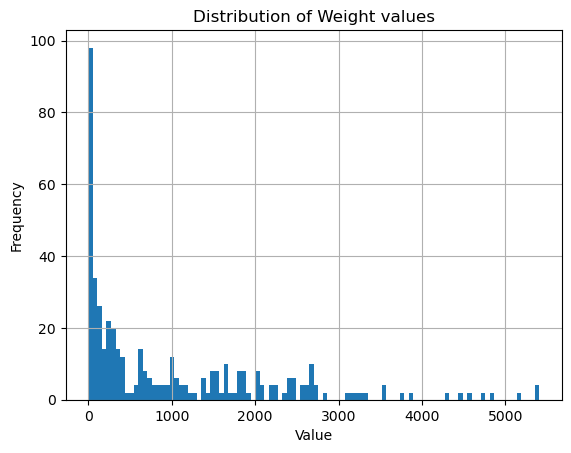

In [9]:
import matplotlib.pyplot as plt

edges['Weight'].hist(bins=100)
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Distribution of Weight values')
plt.show()

The histogram above indicates a lot of weak stylistic links with weight below 1000. We will set the treshold to 1000 to create a network that is less cluttered, and lays more emphasis on strong stylistic similiarities.

In [10]:
edges = edges[edges['Weight'] >= 1000]
edges

,Source,Target,Weight,Type
0,0,1,2737,undirected
1,0,5,1037,undirected
3,0,15,3140,undirected
12,1,0,2737,undirected
15,1,5,4552,undirected
...,...,...,...,...
456,41,42,2703,undirected
458,42,23,1623,undirected
463,42,41,2703,undirected
468,43,29,1858,undirected


We save our tresholded edges dataframe to a csv.

In [11]:
edges.to_csv("edges.csv", index=False)

This direcotry now contains the nodes and edges tables needed for network analysis in Gephi, including the metadata that was still missing from in the Stylo output. A project file for Gephi will be uploaded in this directory as well, so you can explore the network in Gephi.